# Capstone Project: 

## In what year will the world's population growth rate drop to zero, and what will the peak population be then? 

#### By - Chinar Kulkarni


![](images/combined_image.jpg)


##### Today, the world population has crossed the 8 billion mark. With the advent of medical science, travel, and improved living standards, the growth rate has risen unprecedentedly over the past century. However, there will come a time when the limits of essential resources like water, food, fuel, and shelter will outweigh the population growth potential. Some parts of the world are already facing extreme shortages of necessities. Hence, it is inevitable that population growth will continue its downward trajectory until it reaches a point when birth and death rates are identical, and world population reaches its maximum. I believe that the answers to the questions above lie hidden in the world population, GDP, and demographic data.

##### In my capstone project, I intend to utilize the World population data and the population growth data to build models that will study the growth curve so far of each country in the world, and use that knowledge to predict the population growth for the near future. This will help us answer the question: When will the resource limits outweigh the growth potential, and will world population growth become zero? 


In [1]:
# Importing all the required libraries

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import plotly.express as px
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_percentage_error
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.linear_model import Lasso
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
import warnings
from scipy.linalg import LinAlgWarning
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings('ignore', category=LinAlgWarning)
warnings.filterwarnings('ignore', category=UserWarning)
warnings.filterwarnings('ignore', category=ConvergenceWarning)
from statsmodels.tsa.ar_model import AutoReg
from sklearn.ensemble import VotingRegressor
import tensorflow as tf
from tensorflow.keras.layers import Dense, LSTM, Dropout
from tensorflow.keras.models import Sequential


In [2]:
# Function to plot and display the model results 

def plotAndDisplayModelResults(model_num, model_name, description, y_train, y_dev, preds_train, preds_dev, preds_future, results_table):

    plt.figure(figsize = (16,5))
    plt.plot(y_train, 'k', label = 'Train data')
    plt.plot(y_dev, 'k', alpha=0.5, label = 'Test data')
    plt.plot(preds_dev, 'r', linewidth=3, label='Test predictions')
    plt.plot(preds_future, 'r', alpha = 0.5, linewidth=3, label='Future predictions')
    plotTitle = "Model " + str(model_num) + " - " + model_name + ": Results\n"
    plt.suptitle(plotTitle,fontsize=20)
    plt.xlabel("\nYear",fontsize=15)
    plt.ylabel("Population",fontsize=20)
    plt.legend(loc='best')
    
    train_mse = mean_squared_error(y_train, preds_train)
    train_mape = mean_absolute_percentage_error(y_train, preds_train)
    test_mse = mean_squared_error(y_dev, preds_dev)
    test_mape = mean_absolute_percentage_error(y_dev, preds_dev)

    print("Model " + str(model_num) + " Results: ")
    print("Training Mean Squared Error = ", f'{train_mse:.2e}')
    print("Training Mean Abs % Error = ", f'{train_mape:.2%}')
    print("Testing Mean Squared Error = ", f'{test_mse:.2e}')
    print("Testing Mean Abs % Error = ", f'{test_mape:.2%}')

    maxima_year, max_pop = calculateMaxima(preds_future)
    results_table.loc[len(results_table)] = [model_num, model_name, description, train_mse, train_mape, test_mse, test_mape, maxima_year, max_pop]
    
    return results_table
    

# Function to calculate the year of the maxima and the max population 
def calculateMaxima(preds_future):
    maxima_year = preds_future.index.min()
    for i in preds_future.index[1:]:
        if preds_future.loc[i]['Prediction'] > preds_future.loc[i - 1]['Prediction']:
            maxima_year = i
        else:
            break
    if maxima_year == preds_future.index.max():
        return "No Maxima", "N/A"
    else:
        print("Year of Max Population: ", maxima_year)
        print("Max Population: " f'{preds_future.max()['Prediction'] / 1_000_000_000:.2f} Billion')
        return str(maxima_year), f'{preds_future.max()['Prediction'] / 1_000_000_000:.2f} Billion'

##### Here are the datasets I have used for this project:

##### 1. World Population Analysis by Hasib Al Muzdadid (https://www.kaggle.com/code/hasibalmuzdadid/world-population-analysis/notebook)
##### 2. Population Growth by each country by Mahmoud Gamil (https://www.kaggle.com/code/mahmoudredagamail/population-growth-by-each-country-1961-2023/notebook)

In [3]:
# Importing the datasets

pop_data = pd.read_csv('data/world_population.csv')
pop_growth_data = pd.read_csv('data/API_SP.POP.GROW_DS2_en_csv_v2_2594848.csv')

##### The first dataset provided the population of each country at the beginning of each decade, starting from 1970. 

In [4]:
pop_data.head()

,Rank,CCA3,Country/Territory,Capital,Continent,2022 Population,2020 Population,2015 Population,2010 Population,2000 Population,1990 Population,1980 Population,1970 Population,Area (km²),Density (per km²),Growth Rate,World Population Percentage
0,36,AFG,Afghanistan,Kabul,Asia,41128771,38972230,33753499,28189672,19542982,10694796,12486631,10752971,652230,63.0587,1.0257,0.52
1,138,ALB,Albania,Tirana,Europe,2842321,2866849,2882481,2913399,3182021,3295066,2941651,2324731,28748,98.8702,0.9957,0.04
2,34,DZA,Algeria,Algiers,Africa,44903225,43451666,39543154,35856344,30774621,25518074,18739378,13795915,2381741,18.8531,1.0164,0.56
3,213,ASM,American Samoa,Pago Pago,Oceania,44273,46189,51368,54849,58230,47818,32886,27075,199,222.4774,0.9831,0.00
4,203,AND,Andorra,Andorra la Vella,Europe,79824,77700,71746,71519,66097,53569,35611,19860,468,170.5641,1.0100,0.00



##### The second dataset provided the percent growth in population for each country every year from 1960.

In [5]:
pop_growth_data.head()

,Country Name,Country Code,1961,1962,1963,1964,1965,1966,1967,1968,...,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023
0,Aruba,ABW,2.179059,1.548572,1.389337,1.215721,1.032841,0.862184,0.388847,-0.085719,...,0.691615,0.637959,0.590062,0.537296,0.494795,0.451970,0.134255,-0.045045,-0.086392,-0.157953
1,Africa Eastern and Southern,AFE,2.660180,2.732633,2.753248,2.806915,2.840787,2.813609,2.830505,2.881589,...,2.774990,2.802586,2.728159,2.655672,2.688371,2.691134,2.678184,2.607472,2.543757,2.531587
2,Afghanistan,AFG,1.925952,2.014879,2.078997,2.139651,2.216007,2.253524,2.292638,2.347351,...,3.657576,3.121341,2.581549,2.866492,2.885208,2.908529,3.134747,2.851358,2.534498,2.665628
3,Africa Western and Central,AFW,2.115789,2.145723,2.190827,2.211360,2.242567,2.272816,2.275721,2.295953,...,2.750731,2.723317,2.713059,2.706266,2.669239,2.633982,2.615646,2.573377,2.539799,2.540864
4,Angola,AGO,1.558355,1.460738,1.410425,1.301745,1.111041,0.875806,0.696698,0.695985,...,3.684429,3.617678,3.586211,3.550987,3.464457,3.395278,3.268348,3.166030,3.096753,3.030996


##### Since I needed as many data points as I can collect, I merged both these datasets, and calculated the actual population each year for every country.

##### In order to correctly merge the datasets by country name, I had to first rename the 'By' column for merge. Also, some country names did not match, so I had to manually inspect the names and match them in the two datasets.

In [6]:
# Renaming the name of the field to be used for merging
pop_data = pop_data.rename(columns={'Country/Territory': 'Country Name'})

# Renaming the country names to match them between the datasets
pop_growth_data.loc[pop_growth_data['Country Name'] == 'Bahamas, The', "Country Name"] = 'Bahamas'
pop_growth_data.loc[pop_growth_data['Country Name'] == 'Brunei Darussalam', "Country Name"] = 'Brunei'
pop_growth_data.loc[pop_growth_data['Country Name'] == 'Cabo Verde', "Country Name"] = 'Cape Verde'
pop_growth_data.loc[pop_growth_data['Country Name'] == 'Congo, Dem. Rep.', "Country Name"] = 'DR Congo'
pop_growth_data.loc[pop_growth_data['Country Name'] == 'Czechia', "Country Name"] = 'Czech Republic'
pop_growth_data.loc[pop_growth_data['Country Name'] == 'Egypt, Arab Rep.', "Country Name"] = 'Egypt'
pop_growth_data.loc[pop_growth_data['Country Name'] == 'Gambia, The', "Country Name"] = 'Gambia'
pop_growth_data.loc[pop_growth_data['Country Name'] == 'Hong Kong SAR, China', "Country Name"] = 'Hong Kong'
pop_growth_data.loc[pop_growth_data['Country Name'] == 'Iran, Islamic Rep.', "Country Name"] = 'Iran'
pop_growth_data.loc[pop_growth_data['Country Name'] == "Cote d'Ivoire", "Country Name"] = 'Ivory Coast'
pop_growth_data.loc[pop_growth_data['Country Name'] == 'Lao PDR', "Country Name"] = 'Laos'
pop_growth_data.loc[pop_growth_data['Country Name'] == 'Macao SAR, China', "Country Name"] = 'Macau'
pop_growth_data.loc[pop_growth_data['Country Name'] == 'Congo, Rep.', "Country Name"] = 'Republic of the Congo'
pop_growth_data.loc[pop_growth_data['Country Name'] == 'Russian Federation', "Country Name"] = 'Russia'
pop_growth_data.loc[pop_growth_data['Country Name'] == 'Sint Maarten (Dutch part)', "Country Name"] = 'Sint Maarten'
pop_growth_data.loc[pop_growth_data['Country Name'] == 'Slovak Republic', "Country Name"] = 'Slovakia'
pop_growth_data.loc[pop_growth_data['Country Name'] == 'St. Kitts and Nevis', "Country Name"] = 'Saint Kitts and Nevis'
pop_growth_data.loc[pop_growth_data['Country Name'] == 'St. Lucia', "Country Name"] = 'Saint Lucia'
pop_growth_data.loc[pop_growth_data['Country Name'] == 'St. Martin (French part)', "Country Name"] = 'Saint Martin'
pop_growth_data.loc[pop_growth_data['Country Name'] == 'St. Vincent and the Grenadines', "Country Name"] = 'Saint Vincent and the Grenadines'
pop_growth_data.loc[pop_growth_data['Country Name'] == 'Micronesia, Fed. Sts.', "Country Name"] = 'Micronesia'
pop_growth_data.loc[pop_growth_data['Country Name'] == 'Syrian Arab Republic', "Country Name"] = 'Syria'
pop_growth_data.loc[pop_growth_data['Country Name'] == 'Turkiye', "Country Name"] = 'Turkey'
pop_growth_data.loc[pop_growth_data['Country Name'] == 'Venezuela, RB', "Country Name"] = 'Venezuela'
pop_growth_data.loc[pop_growth_data['Country Name'] == 'Viet Nam', "Country Name"] = 'Vietnam'
pop_growth_data.loc[pop_growth_data['Country Name'] == 'Virgin Islands (U.S.)', "Country Name"] = 'United States Virgin Islands'
pop_growth_data.loc[pop_growth_data['Country Name'] == 'Yemen, Rep.', "Country Name"] = 'Yemen'
pop_growth_data.loc[pop_growth_data['Country Name'] == "Korea, Dem. People's Rep.", "Country Name"] = 'North Korea'
pop_growth_data.loc[pop_growth_data['Country Name'] == 'Korea, Rep.', "Country Name"] = 'South Korea'
pop_growth_data.loc[pop_growth_data['Country Name'] == 'Kyrgyz Republic', "Country Name"] = 'Kyrgyzstan'
pop_growth_data.loc[pop_growth_data['Country Name'] == 'Czechia', "Country Name"] = 'CzechRepublic'

# Merging the two datasets
data = pd.merge(pop_data, pop_growth_data, on='Country Name', how='inner')[['Country Name','Country Code','Continent','1970 Population','1970','1971','1972','1973','1974','1975','1976','1977','1978','1979','1980','1981','1982','1983','1984','1985','1986','1987','1988','1989','1990','1991','1992','1993','1994','1995','1996','1997','1998','1999','2000','2001','2002','2003','2004','2005','2006','2007','2008','2009','2010','2011','2012','2013','2014','2015','2016','2017','2018','2019','2020','2021','2022','2023']]


##### After merging the datasets, I now calculate the population of each country for every year starting 1970, based on the percent growth every year.

In [7]:
# Calculating the population of each country every year

exclude = ['Country Name','Country Code','Continent']
prev = []
for col in [c for c in data.columns if c not in exclude]:
    if(col != '1970 Population'):
        data[col] = round(prev * (1 + (data[col] / 100)))
    prev = data[col]

data.head()

,Country Name,Country Code,Continent,1970 Population,1970,1971,1972,1973,1974,1975,...,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023
0,Afghanistan,AFG,Asia,10752971,11014610.0,11280653.0,11554705.0,11846394.0,12144095.0,12434738.0,...,31766835.0,32758386.0,33604060.0,34567318.0,35564657.0,36599065.0,37746353.0,38822637.0,39806596.0,40867692.0
1,Albania,ALB,Europe,2324731,2384031.0,2441795.0,2502717.0,2561845.0,2620696.0,2681002.0,...,3209228.0,3199883.0,3194767.0,3191829.0,3183954.0,3170390.0,3152185.0,3122967.0,3084998.0,3049569.0
2,Algeria,DZA,Africa,13795915,14104234.0,14422009.0,14754894.0,15104996.0,15475457.0,16047955.0,...,39102148.0,39884170.0,40679234.0,41475328.0,42264738.0,43042175.0,43787862.0,44513735.0,45238570.0,45941586.0
3,American Samoa,ASM,Oceania,27075,27763.0,28289.0,28767.0,29241.0,29732.0,30301.0,...,52949.0,52081.0,51140.0,50132.0,49068.0,47937.0,46776.0,45592.0,44814.0,44449.0
4,Andorra,AND,Europe,19860,21324.0,22839.0,24402.0,26016.0,27679.0,29369.0,...,74395.0,74525.0,75345.0,76680.0,77892.0,79261.0,80657.0,82030.0,82846.0,83120.0


##### In order to better understand the data, I have plotted the population of the highest populated countries for each year since 1970. Since India and China dominate the population charts, I plotted the two countries separately, and the rest of the top 10 countries separately, in order to better view the trends of each country.

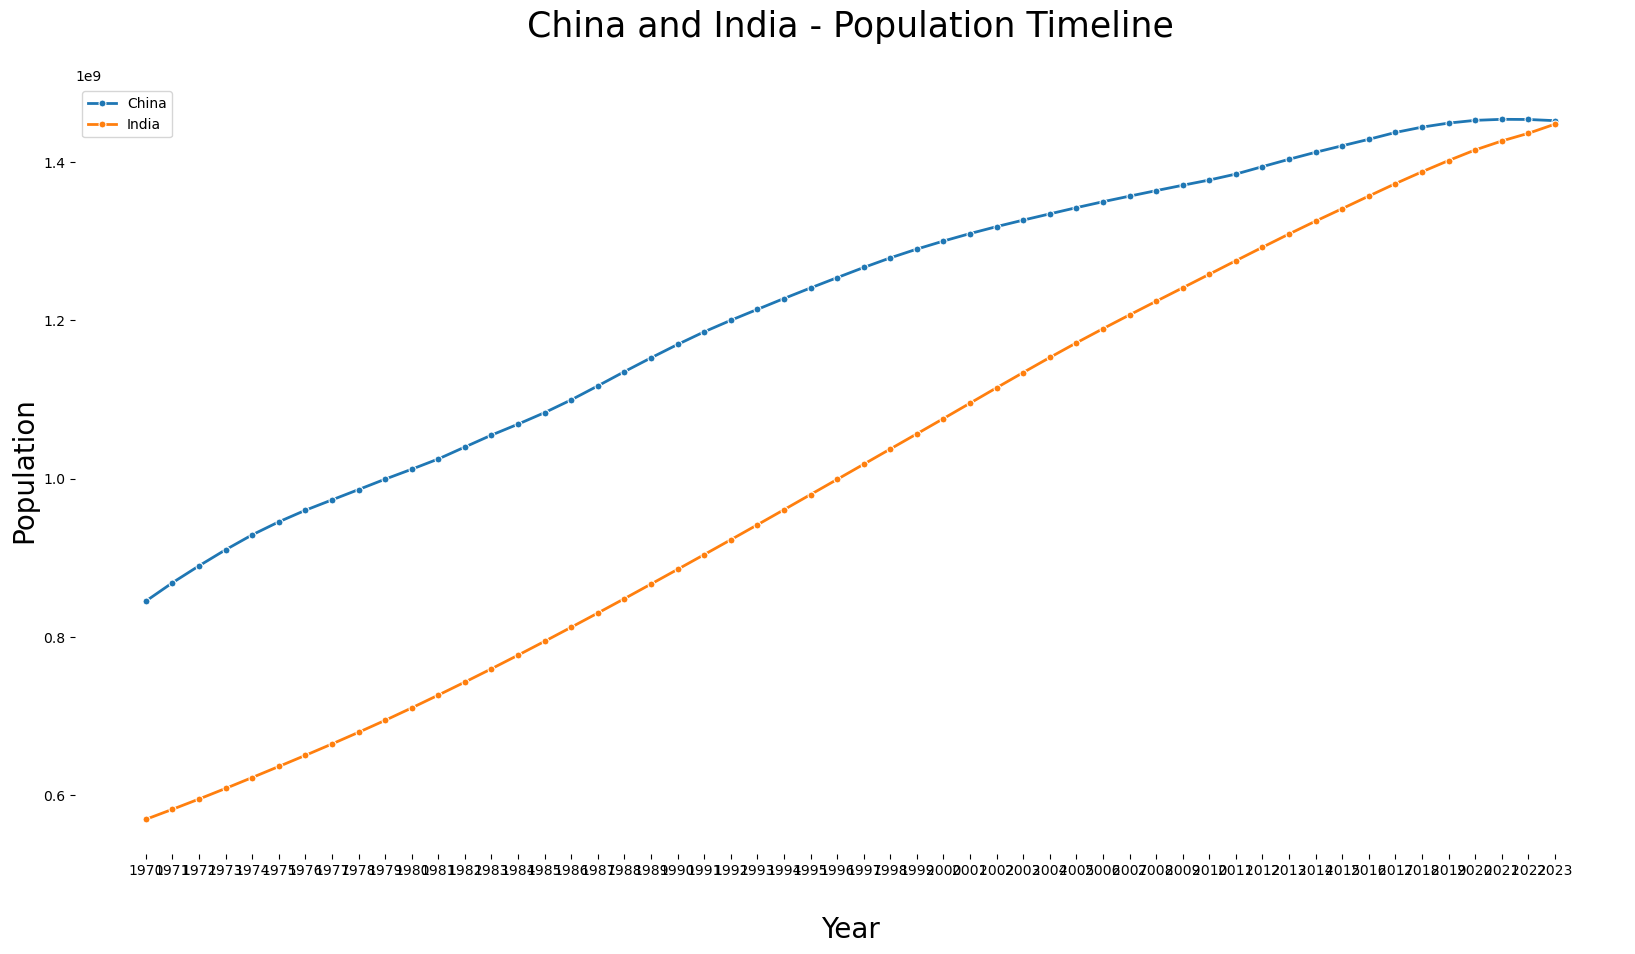

In [8]:
# Plotting the population of India and China for each year from 1970 to 2023

india_and_china = ['India','China']

plot_data = data[data["Country Name"].isin(india_and_china)].set_index("Country Name").drop(columns = ['Country Code','Continent','1970 Population'])

_, axs = plt.subplots(figsize=(20,10))

for col in plot_data.T.columns:
    sns.lineplot(x=plot_data.T.index ,y=plot_data.T[col].values,data=plot_data.T, ax=axs,marker="o",linewidth=2,markersize=5, label = col)

axs.set_title("China and India - Population Timeline\n",fontsize=25)
axs.set_xlabel("\nYear",fontsize=20)
axs.set_ylabel("Population",fontsize=20)

sns.despine(left=True, bottom=True)
plt.show()

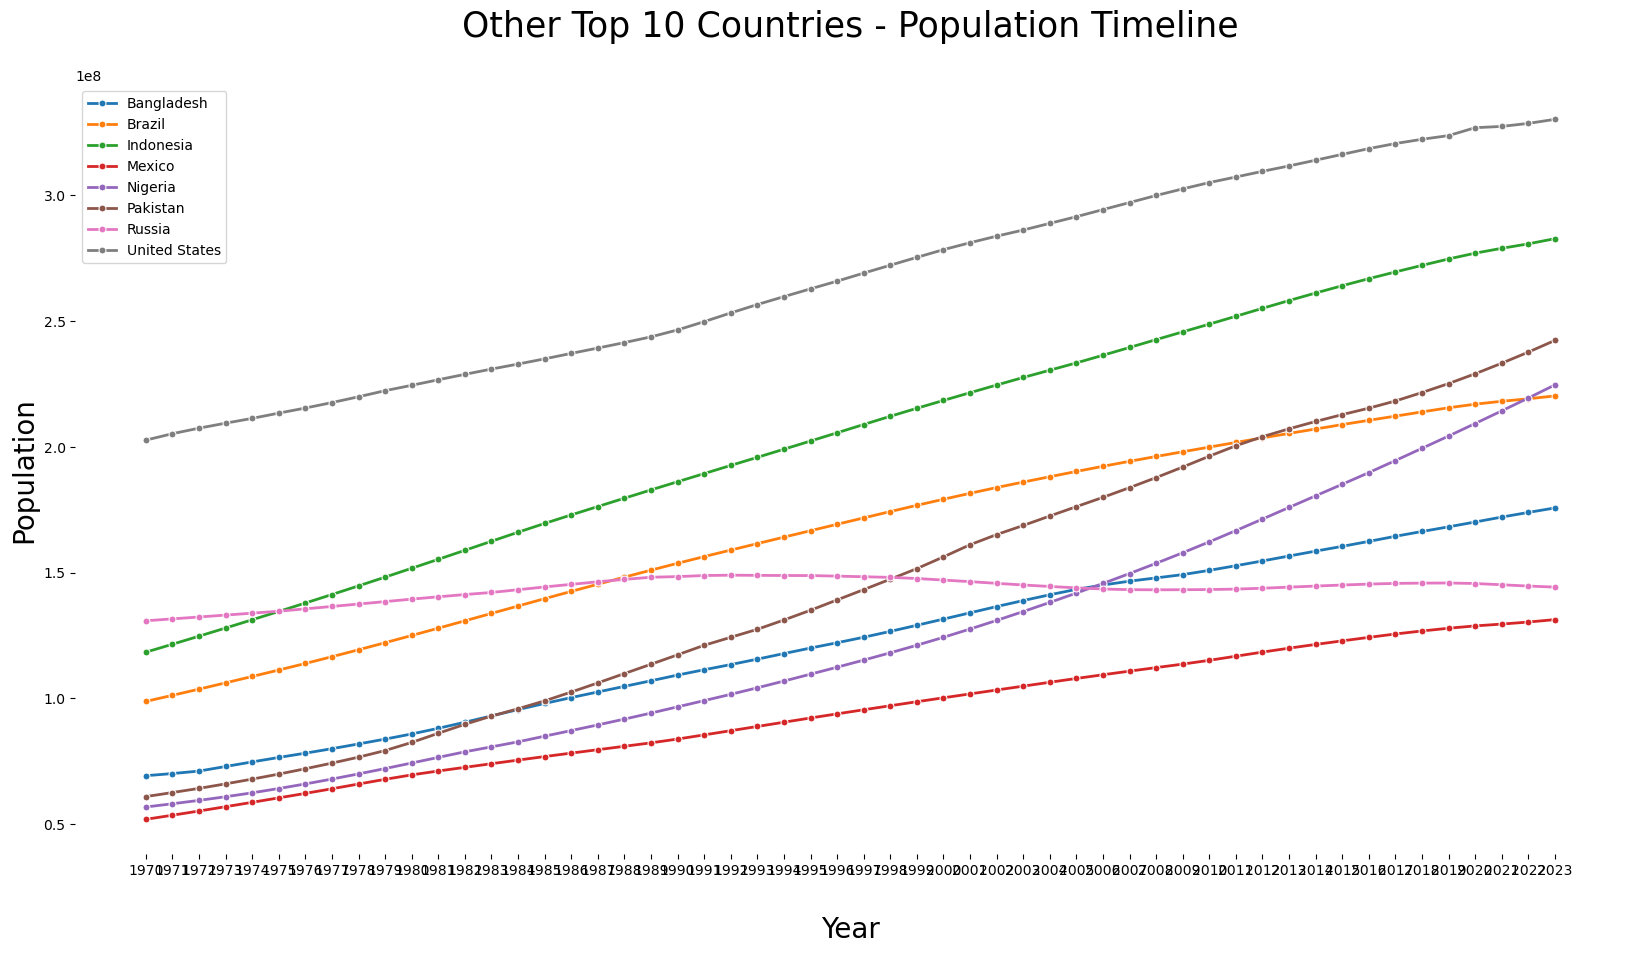

In [9]:
# Plotting the population for the rest of the top 10 countries

top_10_countries_excl_Ind_Chn = data[~data["Country Name"].isin(['India','China'])].sort_values(by = '2023', ascending = False).head(8)['Country Name']

plot_data_excl_Ind_Chn = data[data["Country Name"].isin(top_10_countries_excl_Ind_Chn)].set_index("Country Name").drop(columns = ['Country Code','Continent','1970 Population'])

_, axs = plt.subplots(figsize=(20,10))

for col in plot_data_excl_Ind_Chn.T.columns:
    sns.lineplot(x=plot_data_excl_Ind_Chn.T.index ,y=plot_data_excl_Ind_Chn.T[col].values,data=plot_data_excl_Ind_Chn.T, ax=axs,marker="o",linewidth=2,markersize=5, label = col)

axs.set_title("Other Top 10 Countries - Population Timeline\n",fontsize=25)
axs.set_xlabel("\nYear",fontsize=20)
axs.set_ylabel("Population",fontsize=20)

sns.despine(left=True, bottom=True)
plt.show()

##### As you can see, each country has different curve shapes, and are at a different stage of population growth. Countries like China, Brazil and Mexico are already seeing a decline in the population growth, as their graphs are strightening in the recent years. On the other hand, countries like Pakistan and Nigeria are seeing a high growth in their population even in the recent years.

##### I now calculate the total population of the world every year in a separate dataframe.

Text(0, 0.5, 'Population')

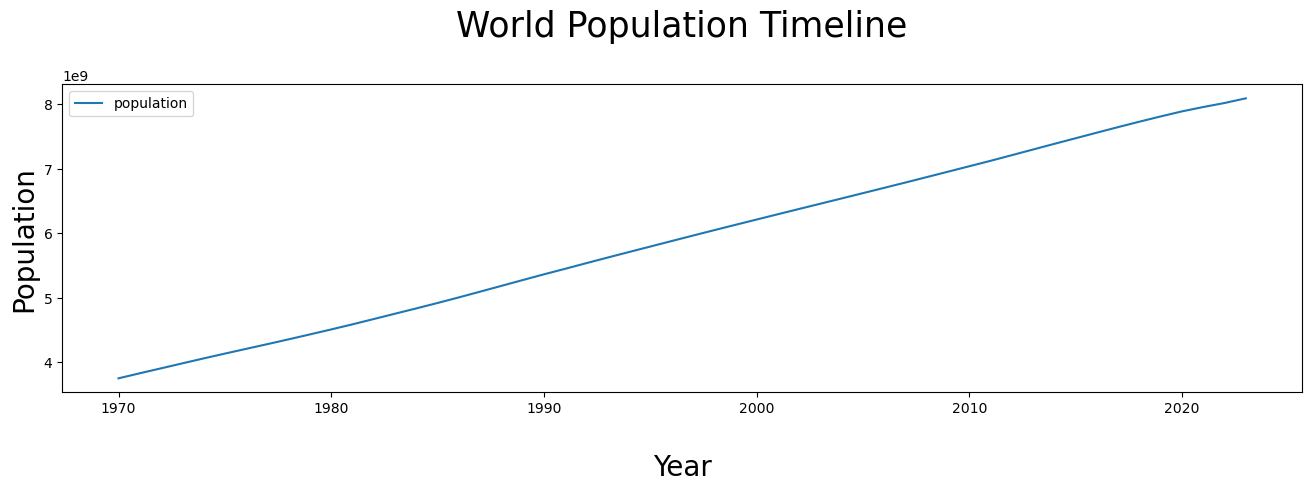

In [10]:
# Calculating the world population for each year from 1970 to 2023

world_data = pd.DataFrame(data.sum())
world_data = world_data[4:].rename(columns = {0: 'population'})

# Changing the year datatype to integer and re-setting it as index

world_data = world_data.reset_index()
world_data['index'] = world_data['index'].astype(int)
world_data = world_data.rename(columns = {'index': 'year'})
world_data = world_data.set_index('year')

# Plotting the world population over the years
axs = world_data.plot(figsize=(16,4))

axs.set_title("World Population Timeline\n",fontsize=25)
axs.set_xlabel("\nYear",fontsize=20)
axs.set_ylabel("Population",fontsize=20)

### Model 1: Degree 2 Feature Engineering Model on the entire world data

##### As you can see above, the world data has a steady upward trend, with no visible seasonal component. Hence, I decided not to use a Time series decomposition model and instead decided to focus mainly on the trend portion. Since my expectation is that the curve will have a gradually decreasing slope, I decided to use a second degree non-Linear Regression model (Feature engineering) as my baseline model. 

##### I set aside 20% of the data (years 2013 to 2023) as my test (dev) dataset, and used the rest of the data for the model training.

##### I created a new DataFrame for the future dataset that contains the years 2024 thru 2080. This Dataframe will be used in our model to predict the future populations.

In [11]:
# Splitting the world data into training and dev sets, and creating the future dataset with no population data

world_X = world_data.reset_index()[['year']]
world_y = world_data.reset_index()['population']

world_X_train = world_X.loc[:42, ['year']]
world_X_dev = world_X.loc[43:53, ['year']]

world_y_train = world_y.loc[:42]
world_y_dev = world_y.loc[43:53]

world_y_train.index = world_data.loc['1970':'2012'].index
world_y_dev.index = world_data.loc['2013':].index

world_X_future = []
for i in range(2023, 2101):
    world_X_future.append({'year': i})
world_X_future = pd.DataFrame(world_X_future)

In [12]:
# Create an empty DataFrame for storing the results with specified columns

result_columns = ['Model Number', 'Technique', 'Description', 'Training Mean Squared Error', 'Training Mean Absolute % Error', 'Testing Mean Squared Error', 'Testing Mean Absolute % Error', 'Maxima Year', 'Maximum Population']
results_table = pd.DataFrame(columns=result_columns)

##### Next, I built a pipeline with the first step to create the second degree polynomial features, followed by Linear Regression on these features. I fit this model on my training data and made predictions for my test dataset. Below, I have plotted the original world population data, along with the model's predictions for the test dataset in Red.

Model 1 Results: 
Training Mean Squared Error =  2.71e+14
Training Mean Abs % Error =  0.29%
Testing Mean Squared Error =  2.02e+15
Testing Mean Abs % Error =  0.44%


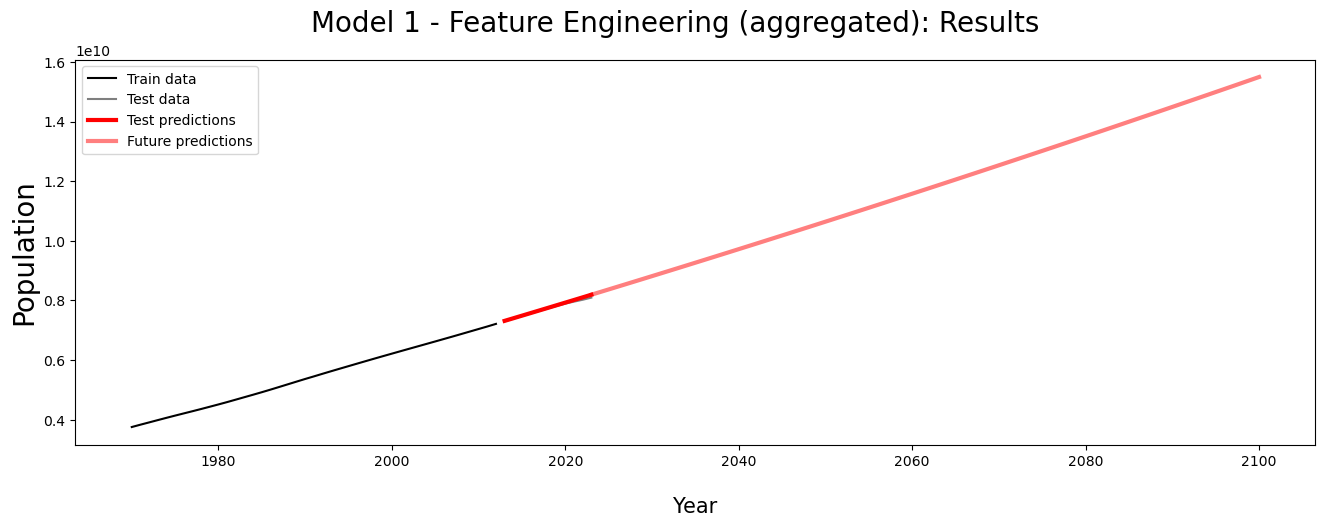

In [13]:
#2nd-degree feature engineering model on aggregated world data

pipelined_model = Pipeline([
	('transform', PolynomialFeatures(degree = 2)),
	('regression', LinearRegression())   
])

pipelined_model.fit(world_X_train, world_y_train)
train_preds = pipelined_model.predict(world_X_train)
dev_preds = pipelined_model.predict(world_X_dev)
future_preds = pipelined_model.predict(world_X_future)
results_train = pd.DataFrame({'year': world_y_train.index, 'Prediction': train_preds}).set_index('year')
results_dev = pd.DataFrame({'year': world_y_dev.index, 'Prediction': dev_preds}).set_index('year')
results_future = pd.DataFrame({'year': world_X_future['year'], 'Prediction': future_preds}).set_index('year')

results_table = plotAndDisplayModelResults(1, "Feature Engineering (aggregated)", "2nd Degree Poly features on Aggregated World Data", world_y_train, world_y_dev, results_train, results_dev, results_future, results_table)

##### It was observed that the baseline model did not provide good results on the dev dataset. One strong reason for that is evident in the plots of country-level data. As we saw previously, each country has a different growth curve and is at a different stage in its growth trajectory. Hence, using a single second-degree regression model on the entire world dataset provides little insight. Instead, we should fit separate models for each country, predict the future populations for each of them, and then add them to get the world population predictions

### Model 2: Individual Hyperparameter-tuned Feature Engineering Models for each country

##### For my second iteration, I used GridSearchCV to find the best-fitting nth degree polynomial feature model for each country, and then added the predictions to get the world population predictions.

##### I iterate over each country, use GridSearchCV to find the best degree parameter for each country, and use that to predict the dev and future populations for the country. I then add them up to get the world population predictions

In [14]:
# Hyperparameter-tuned Feature Engineering Model on individual country data
best_params = []

country_names = data['Country Name']
world_results = []
for country in country_names:
        
    country_data = data[data['Country Name'] == country]
    country_data = country_data.drop(columns = ['Country Name','Country Code','Continent','1970 Population']).T
    country_data = country_data.rename(columns = {country_names.eq(country).argmax(): 'population'})
    
    country_data = country_data.reset_index()
    country_data['index'] = country_data['index'].astype(int)
    country_data = country_data.rename(columns = {'index': 'year'})
    country_data = country_data.set_index('year')
    
    X = country_data.reset_index()[['year']]
    y = country_data.reset_index()['population']
    
    if y.isna().sum() > 0:
        continue
    
    X_train = X.loc[:42, ['year']]
    X_dev = X.loc[43:53, ['year']]
    
    y_train = y.loc[:42]
    y_dev = y.loc[43:53]

    params = {'transform__degree': [2,3,4]}
    
    pipelined_model = Pipeline([
    	('transform', PolynomialFeatures()),
    	('regression', LinearRegression())   
    ])

    model_finder = GridSearchCV(estimator = pipelined_model, param_grid = params, scoring = 'neg_mean_squared_error', cv = 5)

    model_finder.fit(X_train, y_train)
    best_model = model_finder.best_estimator_
    
    preds_train = best_model.predict(X_train)
    results_train = pd.DataFrame({'year': X_train.index, 'Prediction': preds_train}).set_index('year')
    
    preds_dev = best_model.predict(X_dev)
    results_dev = pd.DataFrame({'year': X_dev.index, 'Prediction': preds_dev}).set_index('year')
    
    preds_future = best_model.predict(world_X_future)
    results_future = pd.DataFrame({'year': world_X_future['year'], 'Prediction': preds_future}).set_index('year')
    
    best_params.append(country + ": Degree: " + str(model_finder.best_params_))
    
    if country_names.eq(country).argmax() == 0:
        world_results_train = results_train
        world_results_dev = results_dev
        world_results_future = results_future
    else:
        world_results_train += results_train
        world_results_dev += results_dev
        world_results_future += results_future

world_results_dev.index = world_y_dev.index    

print("Sample degree parameters used for the first 5 countries:")
best_params[:5]

Sample degree parameters used for the first 5 countries:


["Afghanistan: Degree: {'transform__degree': 2}",
 "Albania: Degree: {'transform__degree': 2}",
 "Algeria: Degree: {'transform__degree': 2}",
 "American Samoa: Degree: {'transform__degree': 3}",
 "Andorra: Degree: {'transform__degree': 4}"]

Model 2 Results: 
Training Mean Squared Error =  7.21e+13
Training Mean Abs % Error =  0.14%
Testing Mean Squared Error =  7.96e+15
Testing Mean Abs % Error =  1.07%
Year of Max Population:  2050
Max Population: 8.90 Billion


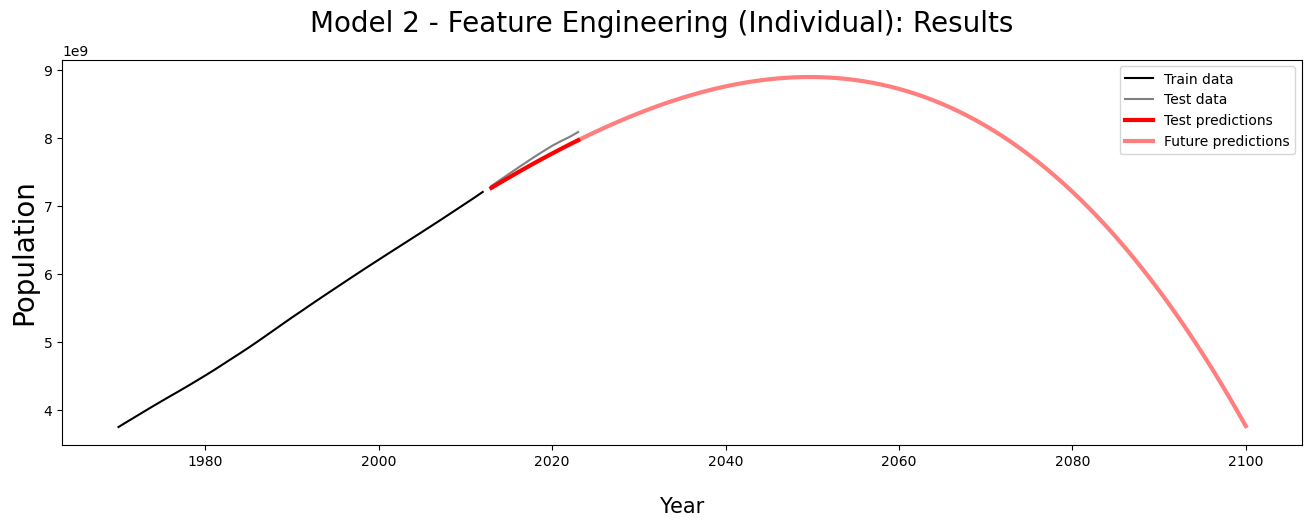

In [15]:
results_table = plotAndDisplayModelResults(2, "Feature Engineering (Individual)", "Hyperparameter-tuned Poly Features on Individual Country Data", world_y_train, world_y_dev, world_results_train, world_results_dev, world_results_future, results_table)

##### As you can see, this model did a better job of predicting the decline in population growth over time. Hence, it could predict the year when growth will become zero and the maximum population. However, the testing mean squared error for this model worsened, and it predicted a steeper decline for the test data than the actual test data showed. 

##### According to the Model 2 predictions, the world will reach its maximum population in 2051, and the population will be 8.903 billion. 

##### I will be covering more models in my final version of the project, along with the analysis of how the factors like Poverty, Hunger, food and water scarcity, infrastructure, etc. govern the population growth of a country. 



### Model 3: Individual Feature Engineering with Ridge Regression Models for each country

##### For my next model, I used the same GridSearchCV to find the best-fitting nth degree polynomial feature model for each country, but added Ridge Regularization with hyper-tuned alpha values for individual country data. This modification did improve the performance, and we got a more accurate representation of the future growth curve.

In [16]:
# Hyperparameter-tuned Feature Engineering Model with Ridge Regularization on individual country data

best_params = []

country_names = data['Country Name']
world_results = []
for country in country_names:
        
    country_data = data[data['Country Name'] == country]
    country_data = country_data.drop(columns = ['Country Name','Country Code','Continent','1970 Population']).T
    country_data = country_data.rename(columns = {country_names.eq(country).argmax(): 'population'})
    
    country_data = country_data.reset_index()
    country_data['index'] = country_data['index'].astype(int)
    country_data = country_data.rename(columns = {'index': 'year'})
    country_data = country_data.set_index('year')
    
    X = country_data.reset_index()[['year']]
    y = country_data.reset_index()['population']
    
    if y.isna().sum() > 0:
        continue
    
    X_train = X.loc[:42, ['year']]
    X_dev = X.loc[43:53, ['year']]
    
    y_train = y.loc[:42]
    y_dev = y.loc[43:53]
    
    params = {'regression__alpha': 10**np.linspace(-5, 4, 10),
             'transform__degree': [2,3,4,5,6]}

    scaled_ridge_model = Pipeline([
        ('transform', PolynomialFeatures(include_bias = False)),
    	('regression', Ridge())
    ])
    
    model_finder = GridSearchCV(
		estimator = scaled_ridge_model,
		param_grid = params,
		scoring = "neg_mean_squared_error")

    model_finder.fit(X_train, y_train)
    best_model = model_finder.best_estimator_
    
    preds_train = best_model.predict(X_train)
    results_train = pd.DataFrame({'year': X_train.index, 'Prediction': preds_train}).set_index('year')
    
    preds_dev = best_model.predict(X_dev)
    results_dev = pd.DataFrame({'year': X_dev.index, 'Prediction': preds_dev}).set_index('year')
    
    preds_future = best_model.predict(world_X_future)
    results_future = pd.DataFrame({'year': world_X_future['year'], 'Prediction': preds_future}).set_index('year')
    
    best_params.append(country + ": Degree: " + str(model_finder.best_params_))
    
    if country_names.eq(country).argmax() == 0:
        world_results_train = results_train
        world_results_dev = results_dev
        world_results_future = results_future
    else:
        world_results_train += results_train
        world_results_dev += results_dev
        world_results_future += results_future

world_results_dev.index = world_y_dev.index  

print("Sample alpha and degree parameters used for the first 5 countries:")
best_params[:5]

Sample alpha and degree parameters used for the first 5 countries:


["Afghanistan: Degree: {'regression__alpha': np.float64(0.001), 'transform__degree': 2}",
 "Albania: Degree: {'regression__alpha': np.float64(0.001), 'transform__degree': 2}",
 "Algeria: Degree: {'regression__alpha': np.float64(0.01), 'transform__degree': 2}",
 "American Samoa: Degree: {'regression__alpha': np.float64(100.0), 'transform__degree': 6}",
 "Andorra: Degree: {'regression__alpha': np.float64(1.0), 'transform__degree': 4}"]

Model 3 Results: 
Training Mean Squared Error =  6.98e+13
Training Mean Abs % Error =  0.14%
Testing Mean Squared Error =  6.76e+15
Testing Mean Abs % Error =  0.99%
Year of Max Population:  2056
Max Population: 9.15 Billion


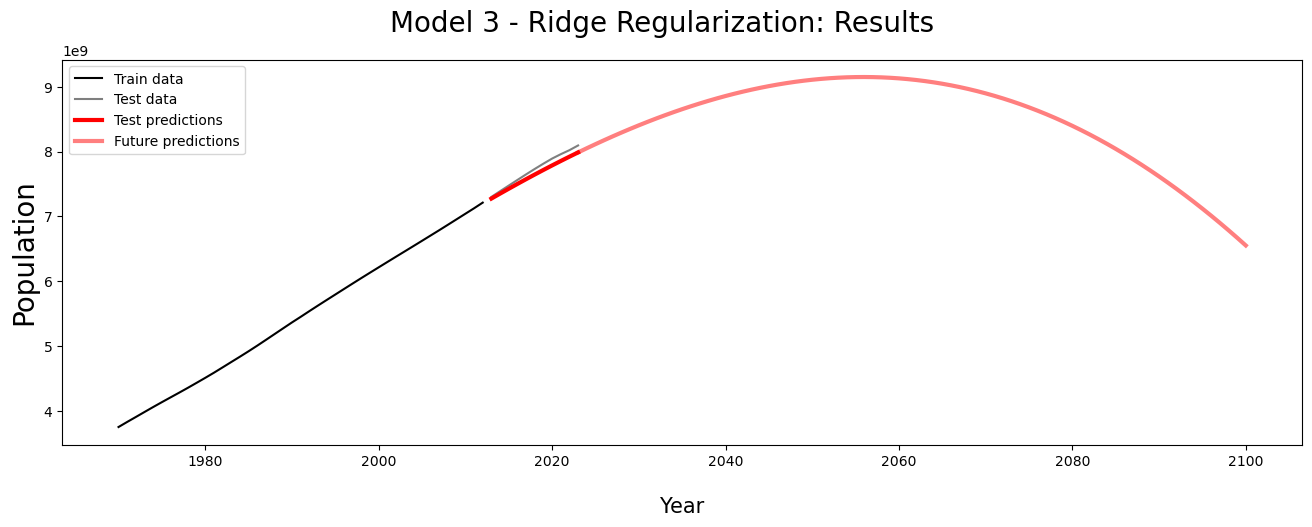

In [17]:
results_table = plotAndDisplayModelResults(3, "Ridge Regularization", "Feature Engineering with Ridge Regression on Individual Country Data", world_y_train, world_y_dev, world_results_train, world_results_dev, world_results_future, results_table)

### Model 4: ARIMA Time Series Model for each country

##### For my next model, I decided to try out a Time Series type of model (ARIMA) to predict the future population based on the past data. As mentioned above, the only component that the population data has is the trend; there is no seasonal component. Also, the Ad-Fuller test performed on the data confirmed that when looking at one country at a time, the trend-removed data is not stationary for most countries, and hence, the ARIMA model cannot be applied.

In [18]:
# ARIMA Time Series Model on individual country data
is_stationary = []

world_X_future_arma = world_X_future.copy()
world_X_future_arma = world_X_future_arma.set_index('year')
world_X_future_arma.index = pd.to_datetime(world_X_future_arma.index, format='%Y')

country_names = data['Country Name']
world_results = []
for country in country_names:
        
    country_data = data[data['Country Name'] == country]
    country_data = country_data.drop(columns = ['Country Name','Country Code','Continent','1970 Population']).T
    country_data = country_data.rename(columns = {country_names.eq(country).argmax(): 'population'})
    
    country_data = country_data.reset_index()
    country_data['index'] = country_data['index'].astype(int)
    country_data = country_data.rename(columns = {'index': 'year'})
    country_data = country_data.set_index('year')
    
    X = country_data.reset_index()[['year']]
    y = country_data.reset_index()['population']
    
    if y.isna().sum() > 0:
        continue
    
    X_train = X.loc[:42, ['year']]
    X_dev = X.loc[43:53, ['year']]
    
    y_train = y.loc[:42]
    y_dev = y.loc[43:53]

    y_train.index = pd.to_datetime(world_y_train.index, format='%Y')
    y_dev.index = pd.to_datetime(world_y_dev.index, format='%Y')
    
    stationary_result = adfuller(y_train.values)
    
    if stationary_result[1] <= 0.05:
        ans1 = 'yes'
    else:
        ans1 = 'no'
    
    is_stationary.append([country, ans1])
    
    if ans1 == 'no':
        continue

    y_train.index = pd.DatetimeIndex(y_train.index.values,
                               freq=y_train.index.inferred_freq)
    
    arma = ARIMA(y_train, order = (1, 0, 1), trend = 'ct').fit()
    
    preds_train = arma.predict(
        start=y_train.index[0], 
        end=y_train.index[-1]
    )
    
    preds_dev = arma.predict(
        start=y_dev.index[0], 
        end=y_dev.index[-1]
    )
    
    future_preds = arma.predict(
        start=world_X_future_arma.index[0], 
        end=world_X_future_arma.index[-1]
    )   
    
    results_train = pd.DataFrame({'year': preds_train.index, 'Prediction': preds_train}).set_index('year')
    
    results_dev = pd.DataFrame({'year': preds_dev.index, 'Prediction': preds_dev}).set_index('year')
    
    results_future = pd.DataFrame({'year': world_X_future_arma.index, 'Prediction': future_preds}).set_index('year')
        
    if isinstance('world_results_train_arma', pd.DataFrame):
        world_results_train_arma += results_train
        world_results_dev_arma += results_dev
        world_results_future_arma += results_future
    else:
        world_results_train_arma = results_train
        world_results_dev_arma = results_dev
        world_results_future_arma = results_future

world_y_dev_arma = world_y_dev.copy()
world_y_train_arma = world_y_train.copy()  
world_results_train_arma.index = world_y_train.index
world_results_dev_arma.index = world_y_dev.index
world_results_future_arma.index = world_results_future.index

is_stationary[:5]

[['Afghanistan', 'no'],
 ['Albania', 'no'],
 ['Algeria', 'no'],
 ['American Samoa', 'no'],
 ['Andorra', 'no']]

### Model 5: Emsemble Technique on individual country data

##### For my next model, I used all the models above and created an ensemble technique that averages the results from each model. This method provided a much more accurate prediction, with lower MSE and MAPE values.

In [19]:
#Emsemble Technique on individual country data

country_names = data['Country Name']
world_results = []
for country in country_names:
        
    country_data = data[data['Country Name'] == country]
    country_data = country_data.drop(columns = ['Country Name','Country Code','Continent','1970 Population']).T
    country_data = country_data.rename(columns = {country_names.eq(country).argmax(): 'population'})
    
    country_data = country_data.reset_index()
    country_data['index'] = country_data['index'].astype(int)
    country_data = country_data.rename(columns = {'index': 'year'})
    country_data = country_data.set_index('year')
    
    X = country_data.reset_index()[['year']]
    y = country_data.reset_index()['population']
    
    if y.isna().sum() > 0:
        continue
    
    X_train = X.loc[:42, ['year']]
    X_dev = X.loc[43:53, ['year']]
    
    y_train = y.loc[:42]
    y_dev = y.loc[43:53]

    params = {'regression__alpha': 10**np.linspace(-5, 4, 10),
             'transform__degree': [2,3,4,5,6]}
    
    degree_3_feature_model = Pipeline([
    	('transform', PolynomialFeatures(degree = 3)),
    	('regression', LinearRegression())   
    ])
    
    degree_4_feature_model = Pipeline([
    	('transform', PolynomialFeatures(degree = 4)),
    	('regression', LinearRegression())   
    ])
    
    degree_5_feature_model = Pipeline([
    	('transform', PolynomialFeatures(degree = 5)),
    	('regression', LinearRegression())   
    ])
    
    degree_6_feature_model = Pipeline([
    	('transform', PolynomialFeatures(degree = 6)),
    	('regression', LinearRegression())   
    ])
    
    scaled_ridge_model_deg_3_alpha_minus_1 = Pipeline([
        ('transform', PolynomialFeatures(degree = 3, include_bias = False)),
    	('regression', Ridge(alpha = 0.1))
    ])
    scaled_ridge_model_deg_3_alpha_minus_2 = Pipeline([
        ('transform', PolynomialFeatures(degree = 3, include_bias = False)),
    	('regression', Ridge(alpha = 0.01))
    ])
    scaled_ridge_model_deg_3_alpha_minus_3 = Pipeline([
        ('transform', PolynomialFeatures(degree = 3, include_bias = False)),
    	('regression', Ridge(alpha = 0.001))
    ])
    
    scaled_ridge_model_deg_4_alpha_minus_1 = Pipeline([
        ('transform', PolynomialFeatures(degree = 4, include_bias = False)),
    	('regression', Ridge(alpha = 0.1))
    ])
    scaled_ridge_model_deg_4_alpha_minus_2 = Pipeline([
        ('transform', PolynomialFeatures(degree = 4, include_bias = False)),
    	('regression', Ridge(alpha = 0.01))
    ])
    scaled_ridge_model_deg_4_alpha_minus_3 = Pipeline([
        ('transform', PolynomialFeatures(degree = 4, include_bias = False)),
    	('regression', Ridge(alpha = 0.001))
    ])
    
    scaled_ridge_model_deg_5_alpha_minus_1 = Pipeline([
        ('transform', PolynomialFeatures(degree = 5, include_bias = False)),
    	('regression', Ridge(alpha = 0.1))
    ])
    scaled_ridge_model_deg_5_alpha_minus_2 = Pipeline([
        ('transform', PolynomialFeatures(degree = 5, include_bias = False)),
    	('regression', Ridge(alpha = 0.01))
    ])
    scaled_ridge_model_deg_5_alpha_minus_3 = Pipeline([
        ('transform', PolynomialFeatures(degree = 5, include_bias = False)),
    	('regression', Ridge(alpha = 0.001))
    ])
    
    scaled_ridge_model_deg_6_alpha_minus_1 = Pipeline([
        ('transform', PolynomialFeatures(degree = 6, include_bias = False)),
    	('regression', Ridge(alpha = 0.1))
    ])
    scaled_ridge_model_deg_6_alpha_minus_2 = Pipeline([
        ('transform', PolynomialFeatures(degree = 6, include_bias = False)),
    	('regression', Ridge(alpha = 0.01))
    ])
    scaled_ridge_model_deg_6_alpha_minus_3 = Pipeline([
        ('transform', PolynomialFeatures(degree = 6, include_bias = False)),
    	('regression', Ridge(alpha = 0.001))
    ])

    voter = VotingRegressor([('f3', degree_3_feature_model), ('f4', degree_4_feature_model), ('f5', degree_5_feature_model), 
                             ('f6', degree_6_feature_model), ('r3_1', scaled_ridge_model_deg_3_alpha_minus_1), 
                             ('r3_2', scaled_ridge_model_deg_3_alpha_minus_2), ('r3_3', scaled_ridge_model_deg_3_alpha_minus_3), 
                             ('r4_1', scaled_ridge_model_deg_4_alpha_minus_1), ('r4_2', scaled_ridge_model_deg_4_alpha_minus_2), 
                             ('r4_3', scaled_ridge_model_deg_4_alpha_minus_3), ('r5_1', scaled_ridge_model_deg_5_alpha_minus_1), 
                             ('r5_2', scaled_ridge_model_deg_5_alpha_minus_2), ('r5_3', scaled_ridge_model_deg_5_alpha_minus_3), 
                             ('r6_1', scaled_ridge_model_deg_6_alpha_minus_1), ('r6_2', scaled_ridge_model_deg_6_alpha_minus_2), 
                             ('r6_3', scaled_ridge_model_deg_6_alpha_minus_3)]).fit(X_train, y_train)
    
    preds_train = voter.predict(X_train)
    results_train_ensemble = pd.DataFrame({'year': X_train.index, 'Prediction': preds_train}).set_index('year')
    
    preds_dev = voter.predict(X_dev)
    results_dev_ensemble = pd.DataFrame({'year': X_dev.index, 'Prediction': preds_dev}).set_index('year')
    
    preds_future = voter.predict(world_X_future)
    results_future_ensemble = pd.DataFrame({'year': world_X_future['year'], 'Prediction': preds_future}).set_index('year')
    
    if country_names.eq(country).argmax() == 0:
        world_results_train_ensemble = results_train_ensemble
        world_results_dev_ensemble = results_dev_ensemble
        world_results_future_ensemble = results_future_ensemble
    else:
        world_results_train_ensemble += results_train_ensemble
        world_results_dev_ensemble += results_dev_ensemble
        world_results_future_ensemble += results_future_ensemble

world_results_dev_ensemble.index = world_y_dev.index  

Model 5 Results: 
Training Mean Squared Error =  7.31e+13
Training Mean Abs % Error =  0.15%
Testing Mean Squared Error =  4.02e+15
Testing Mean Abs % Error =  0.77%
Year of Max Population:  2075
Max Population: 9.88 Billion


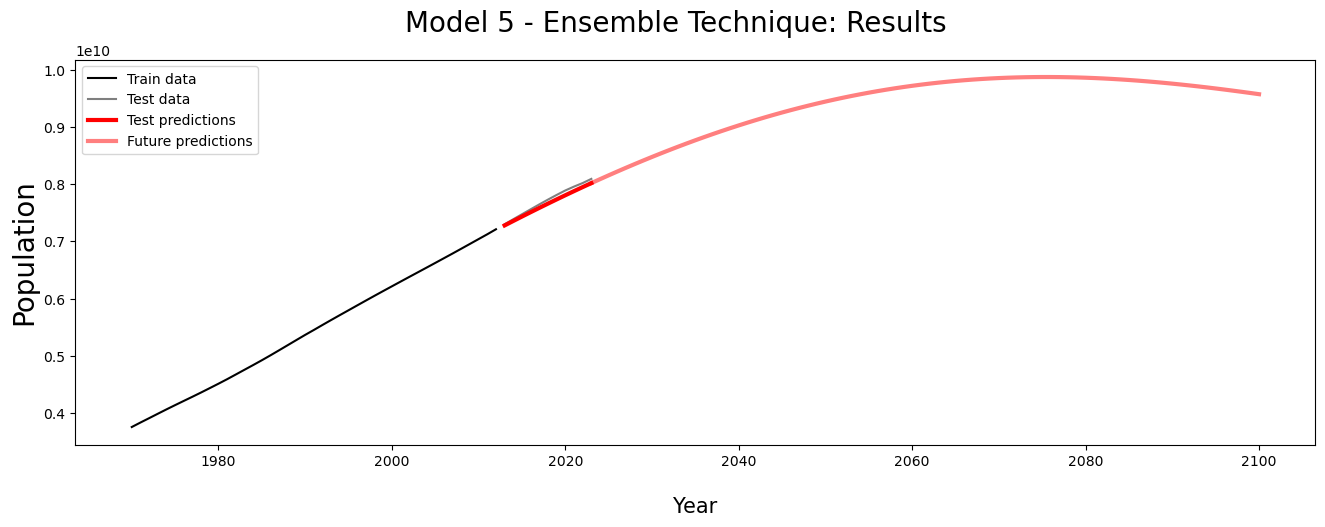

In [20]:
results_table = plotAndDisplayModelResults(5, "Ensemble Technique", "Aggregate results of all previous models on Individual Country Data", world_y_train, world_y_dev, world_results_train_ensemble, world_results_dev_ensemble, world_results_future_ensemble, results_table)

##### This model provided the best results, with the year 2076 predicted as the maxima year, with a maximum population of 9.8 Billion.

### Model 6: Deep Neural Network models on individual country data

##### As a final model, I wanted to use a Deep Neural Network on individual-country data to see whether it can predict the curve's non-linear behavior. I tried it on one country at a time (India; see below), and utilized non-linear activation functions like GELU and Swish. With large epoch and batch-size values, I was able to see the non-linear results. However, due to resource constraints, I could not successfully fit the models on all countries to get the world growth curve. Hence, I had to reduce both the epoch and batch_size values to make it work. This model, however, did not correctly predict the maxima, and instead predicted a linearly increasing graph. 

In [21]:
india_data = pd.DataFrame(data[data['Country Name'].isin(['India'])].sum())
india_data = india_data[4:].rename(columns = {0: 'population'})

india_data = india_data.reset_index()
india_data['index'] = india_data['index'].astype(int)
india_data = india_data.rename(columns = {'index': 'year'})
india_data = india_data.set_index('year')

india_X = india_data.reset_index()[['year']]
india_y = india_data.reset_index()['population']

india_X_train = india_X.loc[:42, ['year']]
india_X_dev = india_X.loc[43:53, ['year']]

india_y_train = india_y.loc[:42]
india_y_dev = india_y.loc[43:53]

india_y_train.index = india_data.loc['1970':'2012'].index
india_y_dev.index = india_data.loc['2013':].index


In [22]:
#Deep Neural Network with 3 hidden layers, a dropout layer, and a linear output layer, applied on individual country data

country_names = data['Country Name']
world_results = []
for country in ['India']: #country_names:
    tf.keras.backend.clear_session()
    print(country)    
    country_data = data[data['Country Name'] == country]
    country_data = country_data.drop(columns = ['Country Name','Country Code','Continent','1970 Population']).T
    country_data = country_data.rename(columns = {country_names.eq(country).argmax(): 'population'})
    
    country_data = country_data.reset_index()
    country_data['index'] = country_data['index'].astype(int)
    country_data = country_data.rename(columns = {'index': 'year'})
    country_data = country_data.set_index('year')
    
    X = country_data.reset_index()[['year']]
    y = country_data.reset_index()['population']
    
    if y.isna().sum() > 0:
        continue
    
    X_train = X.loc[:42, ['year']]
    X_dev = X.loc[43:53, ['year']]
    
    y_train = y.loc[:42]
    y_dev = y.loc[43:53]

    X_train_array = X_train.to_numpy()
    X_dev_array = X_dev.to_numpy()
    world_X_future_array = world_X_future.to_numpy()
    y_train_array = y_train.to_numpy()
    y_dev_array = y_dev.to_numpy()
    
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train_array)
    X_dev_scaled = scaler.transform(X_dev_array)
    world_X_future_scaled = scaler.transform(world_X_future_array)
    
    scaler_y = StandardScaler()
    y_train_scaled = scaler_y.fit_transform(y_train_array.reshape(-1, 1))

    new_model = Sequential([
        Dense(64, activation='swish', input_shape=(X_train_array.shape[1],)),
        Dropout(0.1), 
        Dense(64, activation='swish'),    
        Dense(64, activation='swish'),    
        Dense(1, activation='linear')
    ])
    
    new_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.005),
    loss='mean_squared_error',
    metrics=['mean_absolute_error']
    )
    
    history = new_model.fit(
        X_train_scaled, y_train_scaled,
        epochs=100,
        batch_size=64,
        validation_data=(X_dev_scaled, scaler_y.transform(y_dev_array.reshape(-1, 1))), 
        verbose=0
    )
    
    preds_train_scaled = new_model.predict(X_train_scaled)    
    preds_dev_scaled = new_model.predict(X_dev_scaled)    
    preds_future_scaled = new_model.predict(world_X_future_scaled)

    # Predict and Inverse Transform back to real-world units
    preds_train = scaler_y.inverse_transform(preds_train_scaled)
    preds_dev = scaler_y.inverse_transform(preds_dev_scaled)
    preds_future = scaler_y.inverse_transform(preds_future_scaled)

    results_train = pd.DataFrame({'year': X_train.index, 'Prediction': pd.DataFrame(preds_train)[0]}).set_index('year')
    results_dev = pd.DataFrame({'year': X_dev.index, 'Prediction': pd.DataFrame(preds_dev)[0]}).set_index('year')
    results_future = pd.DataFrame({'year': world_X_future['year'], 'Prediction': pd.DataFrame(preds_future)[0]}).set_index('year')
    
    india_results_train = results_train
    india_results_dev = results_dev
    india_results_future = results_future

india_results_dev.index = india_y_dev.index    


India
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 111ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step


Model 6 Results: 
Training Mean Squared Error =  2.77e+13
Training Mean Abs % Error =  0.53%
Testing Mean Squared Error =  1.06e+15
Testing Mean Abs % Error =  2.00%


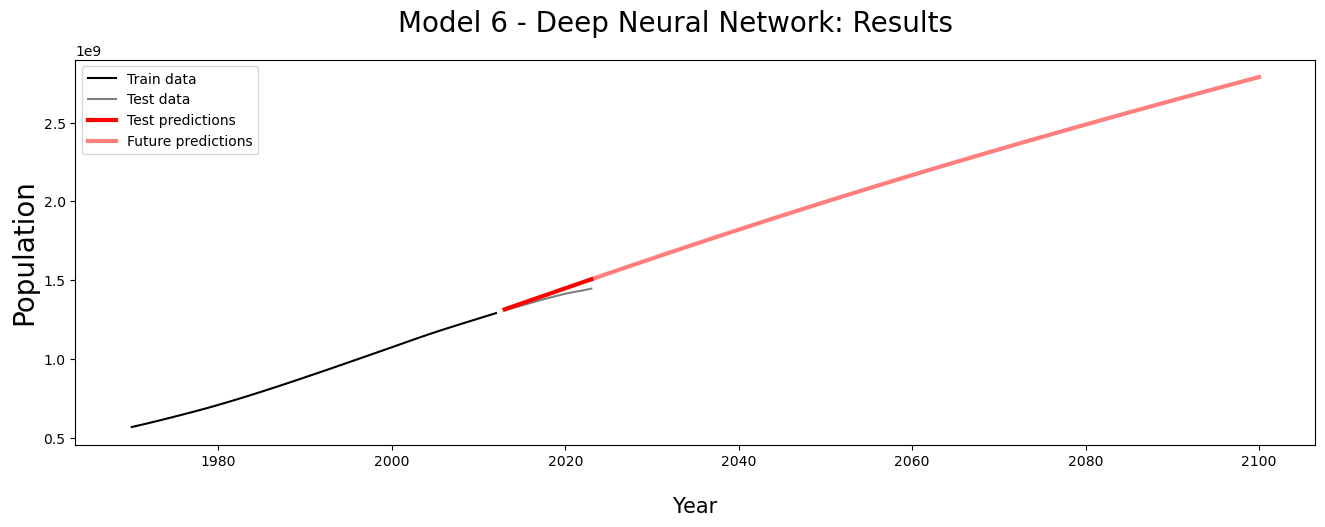

In [23]:
results_table = plotAndDisplayModelResults(6, "Deep Neural Network", "3 + 1 layer DNN on Individual Country Data (Low Epoch and Batch Size)", india_y_train, india_y_dev, india_results_train, india_results_dev, india_results_future, results_table)

## Findings and Conclusions

##### Here is the results table that summarizes the model performance and results

In [24]:
results_table_formatted = results_table.style.format({'Training Mean Squared Error': '{:.2e}', 'Training Mean Absolute % Error': '{:.2%}', 'Testing Mean Squared Error': '{:.2e}', 'Testing Mean Absolute % Error': '{:.2%}'})
results_table_formatted

,Model Number,Technique,Description,Training Mean Squared Error,Training Mean Absolute % Error,Testing Mean Squared Error,Testing Mean Absolute % Error,Maxima Year,Maximum Population
0,1,Feature Engineering (aggregated),2nd Degree Poly features on Aggregated World Data,2.71e+14,0.29%,2.02e+15,0.44%,No Maxima,N/A
1,2,Feature Engineering (Individual),Hyperparameter-tuned Poly Features on Individual Country Data,7.21e+13,0.14%,7.96e+15,1.07%,2050,8.90 Billion
2,3,Ridge Regularization,Feature Engineering with Ridge Regression on Individual Country Data,6.98e+13,0.14%,6.76e+15,0.99%,2056,9.15 Billion
3,5,Ensemble Technique,Aggregate results of all previous models on Individual Country Data,7.31e+13,0.15%,4.02e+15,0.77%,2075,9.88 Billion
4,6,Deep Neural Network,3 + 1 layer DNN on Individual Country Data (Low Epoch and Batch Size),2.77e+13,0.53%,1.06e+15,2.00%,No Maxima,N/A


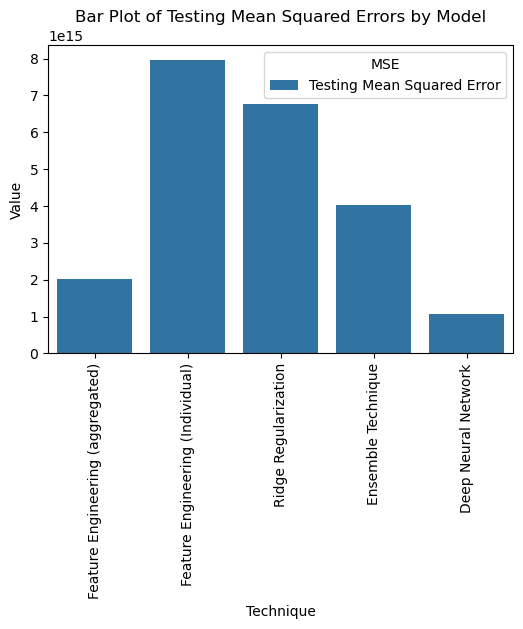

In [25]:
results_table_melted = results_table.melt(id_vars='Technique', var_name='MSE', value_name='Value',
                            value_vars=['Testing Mean Squared Error'])

# Plot side-by-side bars
plt.figure(figsize=(6, 4))
ax = sns.barplot(data=results_table_melted, x='Technique', y='Value', hue='MSE')
plt.title("Bar Plot of Testing Mean Squared Errors by Model")
ax.tick_params(axis='x', labelrotation=90)
plt.show()

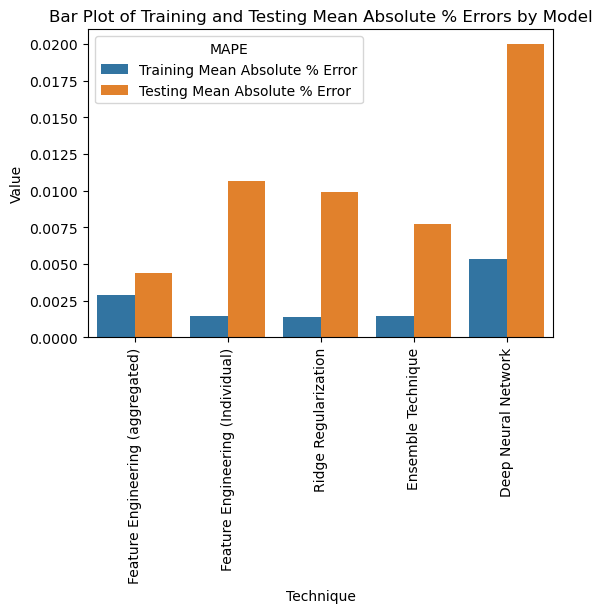

In [26]:
results_table_melted = results_table.melt(id_vars='Technique', value_vars=['Training Mean Absolute % Error', 'Testing Mean Absolute % Error'],
                    var_name='MAPE', value_name='Value')

# Plot side-by-side bars
plt.figure(figsize=(6, 4))
ax = sns.barplot(data=results_table_melted, x='Technique', y='Value', hue='MAPE')
plt.title("Bar Plot of Training and Testing Mean Absolute % Errors by Model")
ax.tick_params(axis='x', labelrotation=90)
plt.show()

#### Here are my findings based on the results:

1. The Time Series Decomposition was not found to be useful in this case, since the population plot consisted only of a trend, without any seasonal component.
2. The 2nd-degree feature engineering model fitted directly on the world population data was used as a baseline model. However, it was found to be difficult to apply models directly to aggregated world data because each country has a different degree of non-linearity in its curve and is at a different stage of growth, depending on many factors that determine population growth.
3. The techniques that modeled the growth individually for each country were found to be more effective and accurate.
4. The Feature Engineering model worked well, since most countries followed a non-linear growth curve.
5. The Ridge regularization technique was a useful addition to the Feature Engineering model and improved the accuracy of the models.
6. The ARIMA Model was not found to be useful in determining the year of population maxima, because it mainly works well with linear trends in the time series data.
7. The Deep Neural Network was found to be too resource-consuming for this modeling task.
8. The **Ensemble Technique model** provided the **best results**, with the lowest MSE and MAPE errors, predicting that the world population will be at its highest in the year **2075**, and the population will reach **9.88 billion** before starting to go down.


### Next Steps

* As a next step, I am planning to go more in depth into the growth curve of each country and to study the factors that govern this curve. 
* There are a lot of factors (like poverty index, food and water shortage, fuel consumption, deforestation, etc.) that can adversely affect a country's population growth. 
* I'm planning to build models that will help me correlate these factors with the growth rate, and better understand how a country can alter its resource efficiency to shift the year of maxima.